# Question 2: the shuttle problem
Each period we either **dispatch** a shuttle (cost 100, takes up to 15 people) or **wait** (2 per person left waiting). 1 to 5 people arrive each period, the station holds at most 200, and the discount rate is 0.95. Lower cost is better. We solve it three ways and plot each.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from shuttle import *

costs, probs = build_tables()          # the same problem is used by all three methods
people = np.arange(MAX_PEOPLE + 1)

## (a) Enumeration, 500 periods
Start at the end of the 500 periods (nothing left to pay) and work backwards, keeping the cheaper action at each step. Plot: best expected cost at time 0 for each number of people waiting.

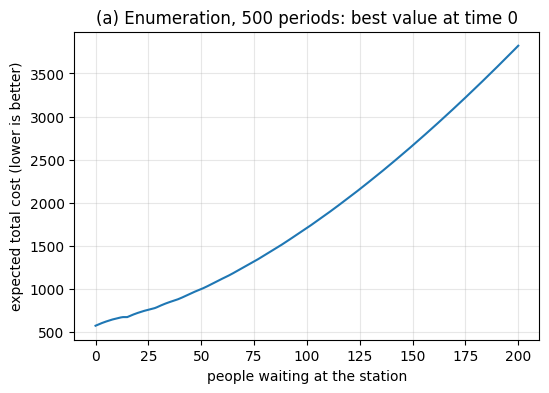

In [2]:
enum_values = enumeration(costs, probs, periods=500)

plt.figure(figsize=(6, 4))
plt.plot(people, enum_values[0])
plt.xlabel('people waiting at the station'); plt.ylabel('expected total cost (lower is better)')
plt.title('(a) Enumeration, 500 periods: best value at time 0'); plt.grid(alpha=.3); plt.show()

## (b) Value iteration, no end date
Same step, repeated forever until the numbers stop changing. Plot: best expected cost for each number of people waiting.

rounds until the numbers stopped changing: 519


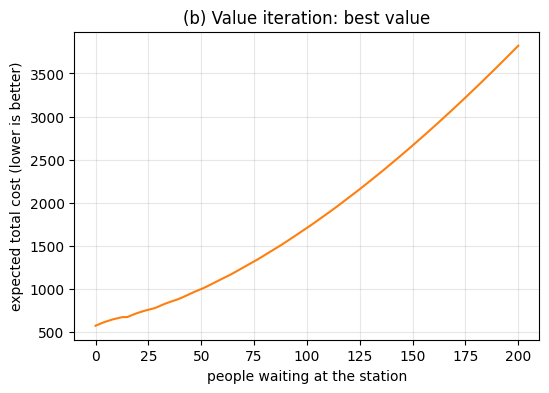

In [3]:
vi_values, vi_policy, vi_rounds = value_iteration(costs, probs)
print('rounds until the numbers stopped changing:', vi_rounds)

plt.figure(figsize=(6, 4))
plt.plot(people, vi_values, color='C1')
plt.xlabel('people waiting at the station'); plt.ylabel('expected total cost (lower is better)')
plt.title('(b) Value iteration: best value'); plt.grid(alpha=.3); plt.show()

(a) and (b) on the same axes. They match because after 500 periods the far future hardly counts.

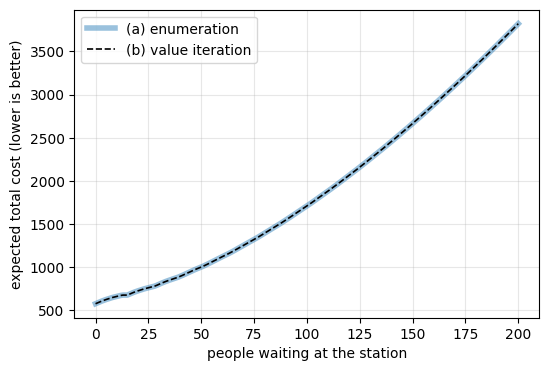

largest difference between (a) and (b): 3.0763658287469298e-09


In [4]:
plt.figure(figsize=(6, 4))
plt.plot(people, enum_values[0], lw=4, alpha=.45, label='(a) enumeration')
plt.plot(people, vi_values, 'k--', lw=1.2, label='(b) value iteration')
plt.xlabel('people waiting at the station'); plt.ylabel('expected total cost (lower is better)')
plt.legend(); plt.grid(alpha=.3); plt.show()
print('largest difference between (a) and (b):', np.max(np.abs(enum_values[0] - vi_values)))

## (c) Policy iteration
Improve a plan instead of the costs: start with 'never dispatch', measure it, switch actions wherever cheaper, repeat. Plot: best action for each number of people waiting.

rounds until the plan stopped changing: 6


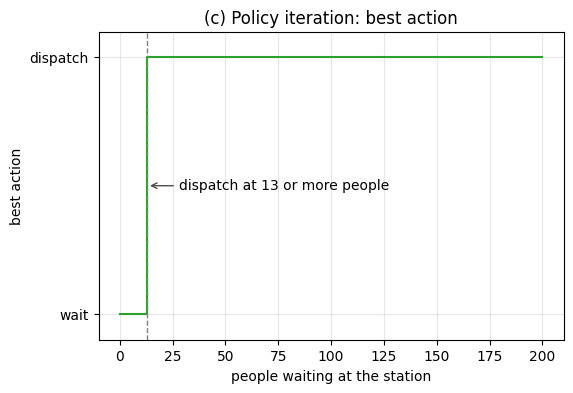

In [5]:
pi_values, pi_policy, pi_rounds = policy_iteration(costs, probs)
cutoff = int(np.argmax(pi_policy == DISPATCH))
print('rounds until the plan stopped changing:', pi_rounds)

plt.figure(figsize=(6, 4))
plt.step(people, pi_policy, where='post', color='C2')
plt.axvline(cutoff, color='0.5', ls='--', lw=1)
plt.annotate(f'dispatch at {cutoff} or more people', xy=(cutoff, 0.5), xytext=(cutoff + 15, 0.5),
             arrowprops=dict(arrowstyle='->', color='0.3'), va='center')
plt.yticks([0, 1], ['wait', 'dispatch']); plt.ylim(-0.1, 1.1)
plt.xlabel('people waiting at the station'); plt.ylabel('best action')
plt.title('(c) Policy iteration: best action'); plt.grid(alpha=.3); plt.show()

## Do the three methods agree?

In [6]:
print('same best action from value iteration and policy iteration:', np.array_equal(vi_policy, pi_policy))
print('largest cost difference, policy iteration vs value iteration:', np.max(np.abs(pi_values - vi_values)))

same best action from value iteration and policy iteration: True
largest cost difference, policy iteration vs value iteration: 1.864464138634503e-09
